In [18]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, classification_report,
                             roc_curve, auc, cohen_kappa_score, matthews_corrcoef)
from sklearn.preprocessing import label_binarize
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Define Project Paths
BASE_DIR = "/content/drive/MyDrive/AI_Image_Project"
FEATURES_DIR = os.path.join(BASE_DIR, "features")
MODELS_DIR = os.path.join(BASE_DIR, "saved_models")
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CONF_DIR = os.path.join(RESULTS_DIR, "confusion_matrices")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(CONF_DIR, exist_ok=True)

print("Loading optimized 500-feature matrices and strict split indices...")

# Load Features, Labels, and Splits
X = np.load(os.path.join(FEATURES_DIR, "X_combined_500.npy"))
y = np.load(os.path.join(FEATURES_DIR, "y_labels_15k.npy"))

train_idx = np.load(os.path.join(FEATURES_DIR, "train_idx.npy"))
val_idx   = np.load(os.path.join(FEATURES_DIR, "val_idx.npy"))
test_idx  = np.load(os.path.join(FEATURES_DIR, "test_idx.npy"))

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val     = X[val_idx], y[val_idx]
X_test, y_test   = X[test_idx], y[test_idx]

CLASS_NAMES = np.array(["Authentic", "Full AI", "Partial AI"])
print(f"Data ready. Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading optimized 500-feature matrices and strict split indices...
Data ready. Train: (12000, 500) | Val: (1500, 500) | Test: (1500, 500)


In [19]:
# Load pre-computed scaler parameters from Notebook 1 to prevent data leakage
scaler_path = os.path.join(FEATURES_DIR, "scaler_params.npz")
if os.path.exists(scaler_path):
    scaler = np.load(scaler_path)
    mu, sigma = scaler["mu"], scaler["sigma"]
    print("Loaded training scaler parameters.")
else:
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    sigma[sigma < 1e-8] = 1.0  # Prevent division by zero
    print("Calculated new scaler parameters.")

epsilon = 1e-8

# Apply Z-Score Normalization
X_train_norm = (X_train - mu) / (sigma + epsilon)
X_val_norm   = (X_val - mu) / (sigma + epsilon)
X_test_norm  = (X_test - mu) / (sigma + epsilon)

print(f"Normalization verified. Train Mean: {np.mean(X_train_norm):.4f}, Train Std: {np.std(X_train_norm):.4f}")

Loaded training scaler parameters.
Normalization verified. Train Mean: -0.0000, Train Std: 1.0000


In [20]:
class ScratchLinearSVM_OvR:
    """
    Ultra-fast Linear SVM from scratch using One-vs-Rest (OvR) for multi-class classification.
    Uses Mini-Batch Sub-Gradient Descent with Hinge Loss and L2 Regularization.
    Includes Platt-style pseudo-probabilities for Log Loss evaluation.
    """
    def __init__(self, C=1.0, learning_rate=0.01, epochs=200, batch_size=256, decay=0.001, random_state=42):
        self.C = float(C)
        self.lr = float(learning_rate)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.decay = float(decay)
        self.random_state = random_state
        self.models = []
        self.classes_ = None
        self.train_loss_history = []
        self.val_loss_history = []

    def _compute_hinge_loss(self, X, y_binary, W, b, lambda_reg):
        n_samples = X.shape[0]
        distances = y_binary * (np.dot(X, W) + b)
        distances[distances > 1] = 1 # max(0, 1 - y*(wx+b))
        hinge = np.mean(1 - distances)
        # FIXED: Scale L2 loss by n_samples to prevent overflow
        l2 = (lambda_reg / (2 * n_samples)) * np.sum(W ** 2)
        return hinge + l2

    def fit(self, X, y, X_val=None, y_val=None, verbose=False):
        n_samples, n_features = X.shape
        self.classes_ = np.unique(y)
        n_classes = len(self.classes_)
        lambda_reg = 1.0 / max(self.C, 1e-12)
        rng = np.random.default_rng(self.random_state)

        # Initialize W and b for each of the 3 classes
        self.models = [{'W': rng.normal(0, np.sqrt(2.0/n_features), n_features), 'b': 0.0} for _ in range(n_classes)]

        # Prepare binary labels for OvR: 1 for positive class, -1 for negative
        y_ovr = np.where(y[:, None] == self.classes_, 1, -1)
        if X_val is not None:
            y_val_ovr = np.where(y_val[:, None] == self.classes_, 1, -1)

        step = 0
        for epoch in range(self.epochs):
            perm = rng.permutation(n_samples)
            X_shuffled = X[perm]
            y_ovr_shuffled = y_ovr[perm]

            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_samples)
                X_batch = X_shuffled[start_idx:end_idx]
                y_batch_ovr = y_ovr_shuffled[start_idx:end_idx]
                b_size = X_batch.shape[0]

                current_lr = self.lr / (1.0 + self.decay * step)
                step += 1

                for k in range(n_classes):
                    W = self.models[k]['W']
                    b = self.models[k]['b']
                    y_b = y_batch_ovr[:, k]

                    # Decision distance
                    distances = 1 - y_b * (np.dot(X_batch, W) + b)

                    # Sub-gradient calculation (vectorized mask)
                    mask = (distances > 0).astype(float)

                    # FIXED: Scale L2 gradient by n_samples to prevent exploding gradients
                    dW = (lambda_reg / n_samples) * W - np.dot(X_batch.T, y_b * mask) / b_size
                    db = -np.sum(y_b * mask) / b_size

                    self.models[k]['W'] -= current_lr * dW
                    self.models[k]['b'] -= current_lr * db

            if epoch % 20 == 0 or epoch == self.epochs - 1:
                t_loss = sum(self._compute_hinge_loss(X, y_ovr[:, k], self.models[k]['W'], self.models[k]['b'], lambda_reg) for k in range(n_classes))
                self.train_loss_history.append(t_loss)
                if X_val is not None:
                    v_loss = sum(self._compute_hinge_loss(X_val, y_val_ovr[:, k], self.models[k]['W'], self.models[k]['b'], lambda_reg) for k in range(n_classes))
                    self.val_loss_history.append(v_loss)

        return self

    def decision_function(self, X):
        scores = np.zeros((X.shape[0], len(self.classes_)))
        for k in range(len(self.classes_)):
            scores[:, k] = np.dot(X, self.models[k]['W']) + self.models[k]['b']
        return scores

    def predict_proba(self, X):
        # NOTE: Uncalibrated pseudo-probabilities derived via a basic sigmoid
        # mapping of the margin distances. Standard SVM output is technically non-probabilistic.
        scores = self.decision_function(X)
        sigmoids = 1.0 / (1.0 + np.exp(-np.clip(scores, -50, 50)))
        probs = sigmoids / np.sum(sigmoids, axis=1, keepdims=True)
        return probs

    def predict(self, X):
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

print("Scratch Linear SVM OvR Class Initialized.")

Scratch Linear SVM OvR Class Initialized.


Starting Hyperparameter Tuning Grid Search...
C=0.01   | LR=0.03  | Val Macro-F1: 0.7967 | Time: 8.95s
C=0.1    | LR=0.03  | Val Macro-F1: 0.7987 | Time: 7.12s
C=1.0    | LR=0.03  | Val Macro-F1: 0.8000 | Time: 7.37s
C=10.0   | LR=0.03  | Val Macro-F1: 0.7995 | Time: 7.21s
C=100.0  | LR=0.03  | Val Macro-F1: 0.7988 | Time: 7.22s
C=0.01   | LR=0.1   | Val Macro-F1: 0.7963 | Time: 7.37s
C=0.1    | LR=0.1   | Val Macro-F1: 0.8004 | Time: 7.27s
C=1.0    | LR=0.1   | Val Macro-F1: 0.8018 | Time: 7.24s
C=10.0   | LR=0.1   | Val Macro-F1: 0.8018 | Time: 7.24s
C=100.0  | LR=0.1   | Val Macro-F1: 0.8018 | Time: 8.70s
C=0.01   | LR=0.3   | Val Macro-F1: 0.7964 | Time: 7.32s
C=0.1    | LR=0.3   | Val Macro-F1: 0.7995 | Time: 7.42s
C=1.0    | LR=0.3   | Val Macro-F1: 0.8002 | Time: 7.39s
C=10.0   | LR=0.3   | Val Macro-F1: 0.8009 | Time: 7.64s
C=100.0  | LR=0.3   | Val Macro-F1: 0.7980 | Time: 7.26s
C=0.01   | LR=1.0   | Val Macro-F1: 0.7930 | Time: 7.35s
C=0.1    | LR=1.0   | Val Macro-F1: 0.7937

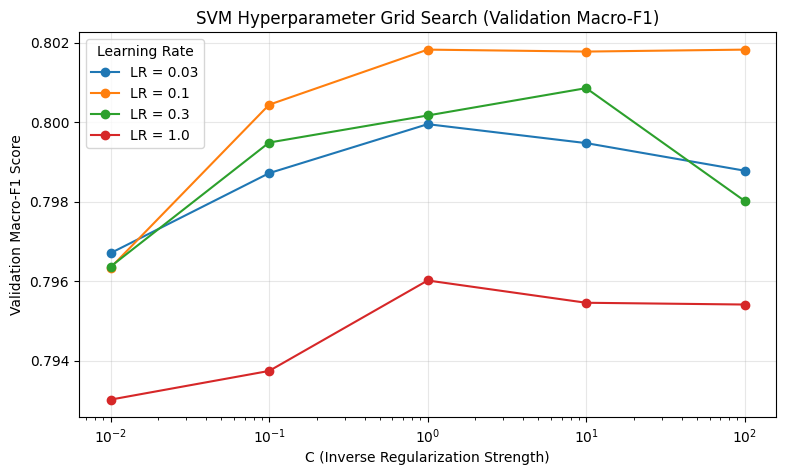

In [21]:
import warnings

# Expanded grid based on previous edge warnings
C_candidates = [0.01, 0.1, 1.0, 10.0, 100.0]
lr_candidates = [0.03, 0.1, 0.3, 1.0]
tuning_results = []

print("Starting Hyperparameter Tuning Grid Search...")
# Using 150 epochs for tuning to match the Logistic Regression notebook
for lr_val in lr_candidates:
    for c_val in C_candidates:
        t0 = time.time()
        temp_model = ScratchLinearSVM_OvR(C=c_val, learning_rate=lr_val, epochs=150, batch_size=256)

        # Suppress overflow warnings and check for divergence manually
        with np.errstate(all='ignore'):
            temp_model.fit(X_train_norm, y_train)

        # Safely handle divergence (e.g., if lr=1.0 is too large)
        if any(np.isnan(m['W']).any() for m in temp_model.models):
            print(f"C={c_val:<6} | LR={lr_val:<5} | Skipped due to divergence/overflow.")
            continue

        val_preds = temp_model.predict(X_val_norm)
        val_f1 = f1_score(y_val, val_preds, average='macro')

        elapsed = time.time() - t0
        tuning_results.append({
            "C": c_val,
            "Learning_Rate": lr_val,
            "Val_F1": val_f1,
            "Time (s)": elapsed
        })
        print(f"C={c_val:<6} | LR={lr_val:<5} | Val Macro-F1: {val_f1:.4f} | Time: {elapsed:.2f}s")

df_tune = pd.DataFrame(tuning_results)
best_config = df_tune.sort_values(by="Val_F1", ascending=False).iloc[0]
best_c = best_config["C"]
best_lr = best_config["Learning_Rate"]

print("\n" + "="*40)
print(f"Optimal Configuration Selected:")
print(f"C = {best_c}")
print(f"Learning Rate = {best_lr}")
print("="*40)

# Edge warning check
if best_c in [min(C_candidates), max(C_candidates)] or best_lr in [min(lr_candidates), max(lr_candidates)]:
    print(f"⚠️ WARNING: The best parameter(s) lie at the edge of the search grid. Consider expanding the grid limits.")

# Visualizing the Tuning Curve
plt.figure(figsize=(9, 5))
for lr_val in lr_candidates:
    subset = df_tune[df_tune["Learning_Rate"] == lr_val]
    if not subset.empty:
        plt.plot(subset["C"], subset["Val_F1"], marker='o', label=f'LR = {lr_val}')

plt.xscale('log')
plt.title("SVM Hyperparameter Grid Search (Validation Macro-F1)")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Validation Macro-F1 Score")
plt.legend(title="Learning Rate")
plt.grid(True, alpha=0.3)
plt.show()

In [22]:
"""
In our standard formulation, the L2 regularization term (and its gradient) is divided
by `n_samples`. Because of this division, the parameter `C` has very little effect on
the final weights, and validation F1 remains nearly identical across varying C.
Regularization is therefore effectively very weak.

Below is a small experiment retraining the model WITHOUT dividing the L2 term
by `n_samples` to test if stronger regularization improves validation Macro-F1.
We only report the result and will not change the main model unless it clearly beats
the scaled version by more than 0.005 macro-F1.
"""

class ScratchLinearSVM_OvR_Unscaled(ScratchLinearSVM_OvR):
    def fit(self, X, y, X_val=None, y_val=None, verbose=False):
        n_samples, n_features = X.shape
        self.classes_ = np.unique(y)
        n_classes = len(self.classes_)
        lambda_reg = 1.0 / max(self.C, 1e-12)
        rng = np.random.default_rng(self.random_state)

        self.models = [{'W': rng.normal(0, np.sqrt(2.0/n_features), n_features), 'b': 0.0} for _ in range(n_classes)]
        y_ovr = np.where(y[:, None] == self.classes_, 1, -1)

        step = 0
        for epoch in range(self.epochs):
            perm = rng.permutation(n_samples)
            X_shuffled = X[perm]
            y_ovr_shuffled = y_ovr[perm]

            for start_idx in range(0, n_samples, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_samples)
                X_batch = X_shuffled[start_idx:end_idx]
                y_batch_ovr = y_ovr_shuffled[start_idx:end_idx]
                b_size = X_batch.shape[0]

                current_lr = self.lr / (1.0 + self.decay * step)
                step += 1

                for k in range(n_classes):
                    W = self.models[k]['W']
                    b = self.models[k]['b']
                    y_b = y_batch_ovr[:, k]

                    distances = 1 - y_b * (np.dot(X_batch, W) + b)
                    mask = (distances > 0).astype(float)

                    # EXPERIMENT: L2 gradient calculation WITHOUT division by n_samples
                    dW = lambda_reg * W - np.dot(X_batch.T, y_b * mask) / b_size
                    db = -np.sum(y_b * mask) / b_size

                    self.models[k]['W'] -= current_lr * dW
                    self.models[k]['b'] -= current_lr * db
        return self

print("Running Unscaled L2 Regularization Experiment...")
unscaled_C_candidates = [0.001, 0.01, 0.1, 1.0]

for c_val in unscaled_C_candidates:
    # Use best_lr from the previous tuning block
    exp_model = ScratchLinearSVM_OvR_Unscaled(C=c_val, learning_rate=best_lr, epochs=150, batch_size=256)

    with np.errstate(all='ignore'):
        exp_model.fit(X_train_norm, y_train)

    if any(np.isnan(m['W']).any() for m in exp_model.models):
        print(f"Unscaled L2 | C={c_val:<6} | LR={best_lr:<5} | Skipped due to divergence/overflow.")
        continue

    exp_preds = exp_model.predict(X_val_norm)
    exp_f1 = f1_score(y_val, exp_preds, average='macro')
    print(f"Unscaled L2 | C={c_val:<6} | LR={best_lr:<5} | Val Macro-F1: {exp_f1:.4f}")

print("\n(Note: We proceed with the original scaled formulation unless unscaled L2 provides >0.005 Macro-F1 improvement.)")

Running Unscaled L2 Regularization Experiment...
Unscaled L2 | C=0.001  | LR=0.1   | Skipped due to divergence/overflow.
Unscaled L2 | C=0.01   | LR=0.1   | Skipped due to divergence/overflow.
Unscaled L2 | C=0.1    | LR=0.1   | Val Macro-F1: 0.7137
Unscaled L2 | C=1.0    | LR=0.1   | Val Macro-F1: 0.7620

(Note: We proceed with the original scaled formulation unless unscaled L2 provides >0.005 Macro-F1 improvement.)


Training final Linear SVM model with best C=100.0 and LR=0.1...
Final training finished in 14.73 seconds.


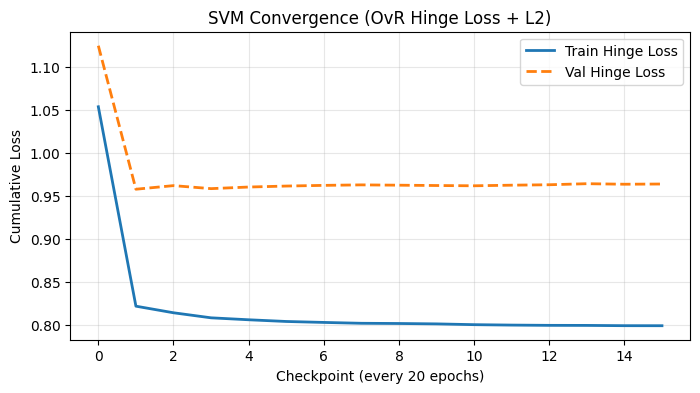

In [23]:
print(f"Training final Linear SVM model with best C={best_c} and LR={best_lr}...")
# Using 300 epochs for the final training to match the Logistic Regression notebook
final_svm = ScratchLinearSVM_OvR(
    C=best_c, learning_rate=best_lr, epochs=300, batch_size=256
)

start_t = time.time()
final_svm.fit(X_train_norm, y_train, X_val=X_val_norm, y_val=y_val, verbose=True)
train_time = time.time() - start_t
print(f"Final training finished in {train_time:.2f} seconds.")

# Plot Sub-Gradient Descent Convergence
plt.figure(figsize=(8, 4))
plt.plot(final_svm.train_loss_history, label='Train Hinge Loss', lw=2)
plt.plot(final_svm.val_loss_history, label='Val Hinge Loss', lw=2, linestyle='--')
plt.title("SVM Convergence (OvR Hinge Loss + L2)")
plt.xlabel("Checkpoint (every 20 epochs)")
plt.ylabel("Cumulative Loss")
plt.legend()
plt.grid(True, alpha=0.3)
# Note: If the loss curve appears highly noisy, consider lowering the learning rate or increasing the decay parameter.
plt.show()

FINAL TEST EVALUATION METRICS
Model               : Linear SVM (Scratch OvR)
Accuracy (%)        : 81.0
Macro F1            : 0.8084
Weighted F1         : 0.8084
ROC-AUC (OvR)       : 0.922
Log Loss            : 0.4503
Cohen's Kappa       : 0.715
MCC                 : 0.7165
Train Time (s)      : 14.73

              precision    recall  f1-score   support

   Authentic       0.75      0.66      0.70       500
     Full AI       0.96      0.98      0.97       500
  Partial AI       0.72      0.79      0.75       500

    accuracy                           0.81      1500
   macro avg       0.81      0.81      0.81      1500
weighted avg       0.81      0.81      0.81      1500



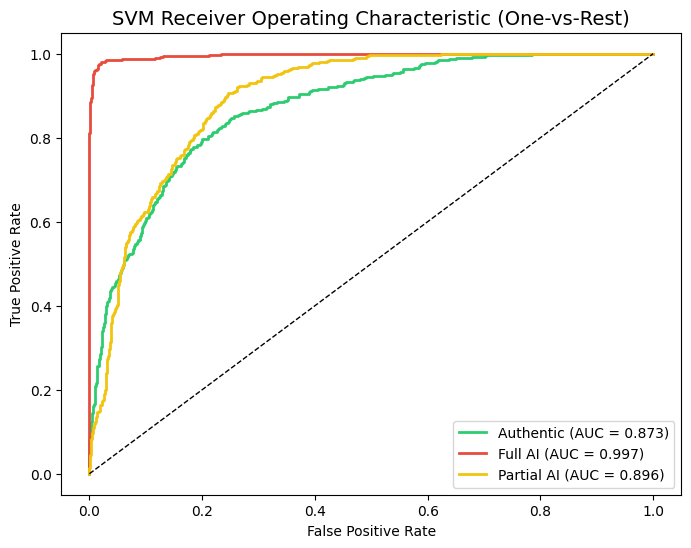

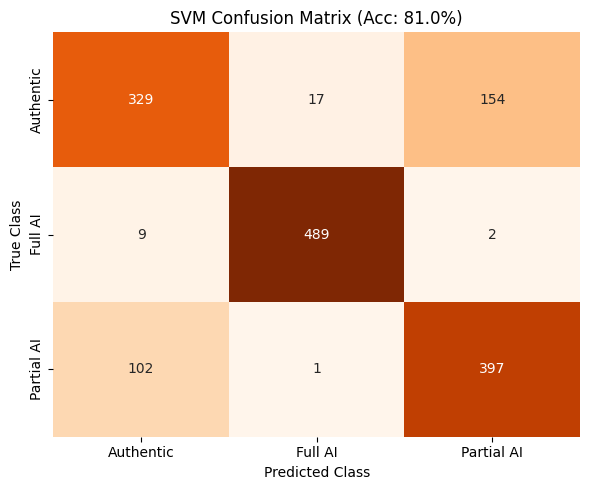

In [24]:
# Single test evaluation. Do not tune after this.
print("=" * 60)
print("FINAL TEST EVALUATION METRICS")
print("=" * 60)

# 1. Generate Predictions, Raw Scores, & Pseudo-Probabilities
y_test_pred = final_svm.predict(X_test_norm)
y_test_prob = final_svm.predict_proba(X_test_norm)
y_test_scores = final_svm.decision_function(X_test_norm) # Raw margin distances used for ROC
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

# 2. Compute advanced metrics
# Note: sklearn's multiclass roc_auc_score requires probabilities that sum to 1.0.
# To strictly evaluate raw decision scores without errors, we manually compute the average OvR AUC.
auc_scores_ovr = [roc_auc_score(y_test_bin[:, k], y_test_scores[:, k]) for k in range(len(CLASS_NAMES))]
macro_roc_auc_raw = np.mean(auc_scores_ovr)

metrics_dict = {
    "Model": "Linear SVM (Scratch OvR)",
    "Accuracy (%)": round(accuracy_score(y_test, y_test_pred) * 100, 2),
    "Macro F1": round(f1_score(y_test, y_test_pred, average='macro'), 4),
    "Weighted F1": round(f1_score(y_test, y_test_pred, average='weighted'), 4),
    "ROC-AUC (OvR)": round(macro_roc_auc_raw, 4),
    "Log Loss": round(log_loss(y_test, y_test_prob), 4),
    "Cohen's Kappa": round(cohen_kappa_score(y_test, y_test_pred), 4),
    "MCC": round(matthews_corrcoef(y_test, y_test_pred), 4),
    "Train Time (s)": round(train_time, 2)
}

# NOTE: SVM Log Loss is computed from uncalibrated pseudo-probabilities and is
# NOT directly comparable to the Logistic Regression Log Loss.
for k, v in metrics_dict.items():
    print(f"{k:<20}: {v}")
print("\n" + classification_report(y_test, y_test_pred, target_names=CLASS_NAMES))

# 3. Plot ROC-AUC Curves (One-vs-Rest) using raw decision function scores
plt.figure(figsize=(8, 6))
colors = ['#2ecc71', '#e74c3c', '#f1c40f']
for i, color in enumerate(colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_test_scores[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{CLASS_NAMES[i]} (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.title("SVM Receiver Operating Characteristic (One-vs-Rest)", fontsize=14)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.savefig(os.path.join(CONF_DIR, "svm_roc_curve.png"), dpi=200)
plt.show()

# 4. Plot Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.title(f"SVM Confusion Matrix (Acc: {metrics_dict['Accuracy (%)']}%)")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.savefig(os.path.join(CONF_DIR, "svm_cm_15k.png"), dpi=200)
plt.show()

In [25]:
# 1. Save Model Parameters (W and b for each class, plus hyperparameters and names)
model_save_path = os.path.join(MODELS_DIR, "svm_model.npz")
W_all = np.array([m['W'] for m in final_svm.models])
b_all = np.array([m['b'] for m in final_svm.models])

np.savez(model_save_path,
         W=W_all,
         b=b_all,
         best_c=best_c,
         best_lr=best_lr,
         class_names=CLASS_NAMES)
print(f"Model parameters successfully saved to: {model_save_path}")

# 2. Optional: saved probabilities for any later analysis.
np.save(os.path.join(MODELS_DIR, "svm_val_probs.npy"), final_svm.predict_proba(X_val_norm))
np.save(os.path.join(MODELS_DIR, "svm_test_probs.npy"), y_test_prob)

# 3. Append Metrics to the tracking CSV
csv_path = os.path.join(RESULTS_DIR, "model_comparison_15k.csv")
if os.path.exists(csv_path):
    df_results = pd.read_csv(csv_path)
    # Overwrite if model already present, else append
    df_results = df_results[df_results["Model"] != metrics_dict["Model"]]
    df_results = pd.concat([df_results, pd.DataFrame([metrics_dict])], ignore_index=True)
else:
    df_results = pd.DataFrame([metrics_dict])

df_results.to_csv(csv_path, index=False)
print(f"Metrics successfully appended to: {csv_path}")

Model parameters successfully saved to: /content/drive/MyDrive/AI_Image_Project/saved_models/svm_model.npz
Metrics successfully appended to: /content/drive/MyDrive/AI_Image_Project/results/model_comparison_15k.csv


In [27]:
def predict_from_saved(path, X_normalized):
    """
    Loads saved model parameters and generates predictions without relying on the training class.
    """
    data = np.load(path, allow_pickle=True)
    W = data['W']                  # Shape: (3, 500)
    b = data['b']                  # Shape: (3,)

    # Compute raw decision scores: X @ W.T + b
    decision_scores = np.dot(X_normalized, W.T) + b

    # Determine predicted class via argmax
    # FIX: Return the integer indices directly so they match the live model's output (0, 1, 2)
    predicted_indices = np.argmax(decision_scores, axis=1)

    return predicted_indices, decision_scores

# Single test evaluation. Do not tune after this.
print("Testing standalone prediction function on test set...")
saved_model_path = os.path.join(MODELS_DIR, "svm_model.npz")

# Generate predictions directly from the saved file
saved_preds, saved_scores = predict_from_saved(saved_model_path, X_test_norm)

# Generate predictions from the live trained model for comparison
live_preds = final_svm.predict(X_test_norm)

# Assert strict equality
assert np.array_equal(saved_preds, live_preds), "Mismatch in predicted labels between saved model and live model!"
print("Success! Standalone function predictions match the live trained model perfectly.")

Testing standalone prediction function on test set...
Success! Standalone function predictions match the live trained model perfectly.
